# Traitement et Nettoyage des Données 

### 1.Import des bibliothèque 

In [2]:
import pandas as pd 
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Chargement des données

In [3]:
df = pd.read_csv('../data/kc_house_data.csv')
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


### Dictionnaire des données (King County House Sales)

* **id** : Identifiant unique attribué à chaque maison vendue
* **date** : Date à laquelle la vente de la maison a eu lieu.
* **price** : Prix de vente de chaque bien.
* **bedrooms** : Nombre de chambres.
* **bathrooms** : Nombre de salles de bain, où la valeur 0,5 désigne une pièce équipée de toilettes mais sans douche.
* **sqft_living** : Surface habitable intérieure de l'appartement exprimée en pieds carrés.
* **sqft_lot** : Surface de l'espace du terrain en pieds carrés.
* **floors** : Nombre d'étages du bien.
* **waterfront** : Variable indicatrice permettant de savoir si l'appartement a une vue sur le front de mer ou non.
* **view** : Indice allant de 0 à 4 évaluant la qualité de la vue offerte par la propriété.
* **condition** : Indice de 1 à 5 évaluant l'état de l'appartement.
* **grade** : Indice de 1 à 13 évaluant le niveau de construction et de design, où 1 à 3 correspond à un niveau insuffisant, 7 à un niveau moyen, et 11 à 13 à un niveau de haute qualité.
* **sqft_above** : Surface habitable de l'espace intérieur située au-dessus du niveau du sol, en pieds carrés.
* **sqft_basement** : Surface habitable de l'espace intérieur située en dessous du niveau du sol (sous-sol), en pieds carrés.
* **yr_built** : Année de construction initiale de la maison.
* **yr_renovated** : Année de la dernière rénovation de la maison.
* **zipcode** : Code postal de la zone où se situe la maison.
* **lat** : Latitude du bien.
* **long** : Longitude du bien.
* **sqft_living15** : Surface habitable intérieure des 15 voisins les plus proches, en pieds carrés.
* **sqft_lot15** : Surface des parcelles de terrain des 15 voisins les plus proches, en pie.pieds carrés[cite: 5].

In [4]:
df.shape

(21613, 21)

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [6]:
df .isna().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [7]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### Prétraitement et typage des variables pour la régression

* **id** : Identifiant unique au format entier (`int64`) sans valeur prédictive ; à exclure de la modélisation pour éviter d'introduire du bruit.
* **date** : Format texte (`object`) ; à convertir en `datetime` pour dériver des variables temporelles numériques (année, mois) captant la saisonnalité.
* **price** : Variable cible quantitative continue (`float64`) à distribution étalée à droite ; application possible d'une transformation logarithmique pour réduire l'impact des biens de luxe sur les erreurs de régression.
* **bedrooms / bathrooms / floors** : Variables numériques discrètes ; à filtrer pour éliminer les anomalies (ex. 33 chambres) et à standardiser pour les modèles linéaires.
* **sqft_living / sqft_lot / sqft_above / sqft_basement / sqft_living15 / sqft_lot15** : Variables de surfaces continues avec forte multicolinéarité ; à standardiser (`StandardScaler`) pour Ridge/Lasso et à surveiller pour supprimer d'éventuelles redondances.
* **waterfront** : Indicateur binaire au format entier (`int64`) ; à typer en booléen pour conserver son statut de variable indicatrice sans subordonner son échelle aux features continuent.
* **view** : Indice de 0 à 4 au format entier (`int64`) ; variable ordinale à encoder (One-Hot pour Ridge/Lasso) afin de capturer l'impact non linéaire de chaque niveau de vue.
* **condition** : Indice de 1 à 5 au format entier (`int64`) ; variable ordinale nécessitant un encodage (One-Hot pour modèles linéaires) pour éviter d'imposer un effet constant.
* **grade** : Indice de 1 à 13 au format entier (`int64`) ; variable ordinale dont l'impact explose sur les notes élevées, nécessitant un encodage One-Hot pour la régression linéaire.
* **yr_built / yr_renovated** : Années au format entier (`int64`) ; à transformer en variables calculées (âge du logement lors de la vente, temps écoulé depuis la rénovation ou variable binaire « rénové oui/non »).
* **zipcode** : Code postal au format entier (`int64`) ; variable catégorielle géographique à convertir en texte puis à encoder (One-Hot ou Target Encoding) pour isoler le facteur quartier.
* **lat / long** : Coordonnées géographiques continues (`float64`) ; à conserver pour les modèles d'arbres ou à standardiser/croiser avec le code postal pour les modèles linéaires.

## Recherche de doublons, valeur manquantes ou abhérentes

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['id'].duplicated().sum()

np.int64(177)

* **Doublons stricts**: Aucune ligne parfaitement identique sur l'ensemble des 21 colonnes ; le jeu de données ne présente aucun doublon brut.
* **Doublons d'identifiant** : 177 transactions concernent des biens vendus plusieurs fois (0,82 % du total) ; nous ne conservons que la vente la plus récente pour éliminer tout risque de fuite de données (*data leakage*).

In [10]:
df.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

**Valeurs nulles**: Aucune valeur manquante.

In [11]:
# Sélection exclusive des variables purement numériques et continues
# On exclut les variables géographiques (lat, long, zipcode), ordinales (grade, condition) et binaires (waterfront)
colonnes_continues = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 
                      'sqft_above', 'sqft_basement', 'sqft_living15', 'sqft_lot15']

print("Détection des valeurs aberrantes (Méthode IQR) :\n" + "-"*65)

# Dictionnaire pour stocker les seuils afin de les réutiliser pour le traitement
seuils_iqr = {}

for col in colonnes_continues:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    seuil_bas = Q1 - 1.5 * IQR
    seuil_haut = Q3 + 1.5 * IQR
    
    # Stockage des seuils pour une utilisation ultérieure (filtrage ou plafonnement)
    seuils_iqr[col] = {'bas': seuil_bas, 'haut': seuil_haut}
    
    # Comptage des valeurs en dehors des limites
    outliers = df[(df[col] < seuil_bas) | (df[col] > seuil_haut)]
    pourcentage = (len(outliers) / len(df)) * 100
    
    # Affichage formaté incluant le seuil haut pour mieux comprendre la limite
    print(f"{col:15} : {len(outliers):4} valeurs aberrantes ({pourcentage:5.2f}%) | Seuil max 'normal' : {seuil_haut:10.2f}")

Détection des valeurs aberrantes (Méthode IQR) :
-----------------------------------------------------------------
price           : 1146 valeurs aberrantes ( 5.30%) | Seuil max 'normal' : 1129575.00
bedrooms        :  546 valeurs aberrantes ( 2.53%) | Seuil max 'normal' :       5.50
bathrooms       :  571 valeurs aberrantes ( 2.64%) | Seuil max 'normal' :       3.62
sqft_living     :  572 valeurs aberrantes ( 2.65%) | Seuil max 'normal' :    4234.50
sqft_lot        : 2425 valeurs aberrantes (11.22%) | Seuil max 'normal' :   19160.00
sqft_above      :  611 valeurs aberrantes ( 2.83%) | Seuil max 'normal' :    3740.00
sqft_basement   :  496 valeurs aberrantes ( 2.29%) | Seuil max 'normal' :    1400.00
sqft_living15   :  544 valeurs aberrantes ( 2.52%) | Seuil max 'normal' :    3665.00
sqft_lot15      : 2194 valeurs aberrantes (10.15%) | Seuil max 'normal' :   17557.50


<Axes: xlabel='sqft_lot', ylabel='price'>

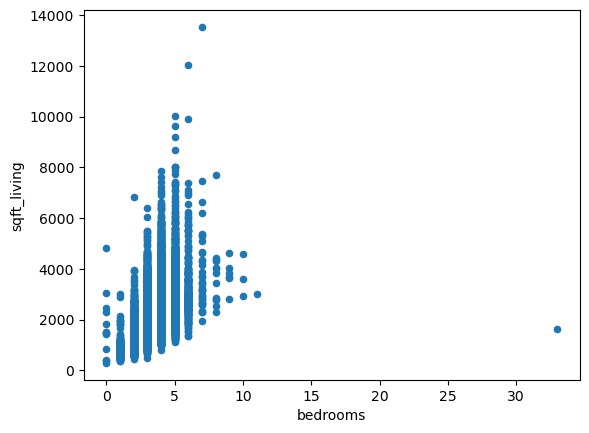

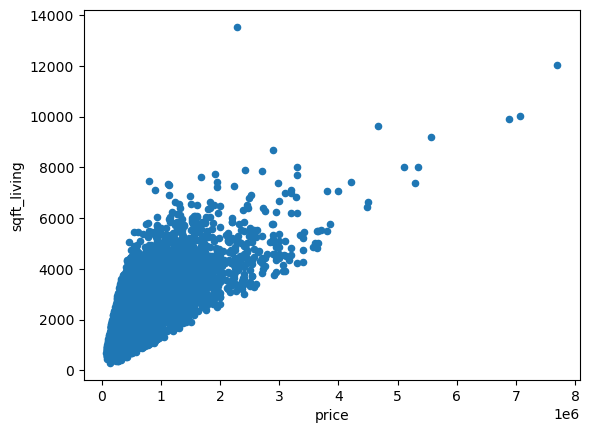

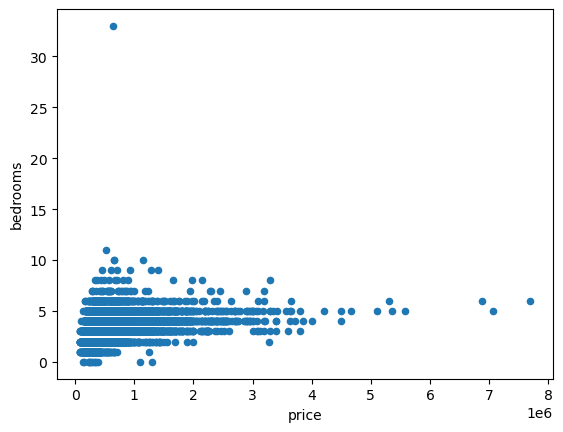

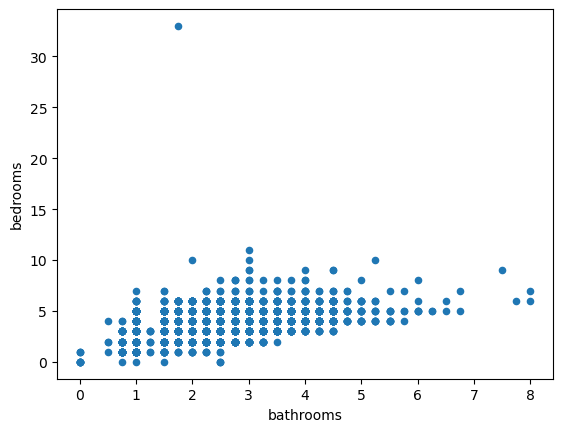

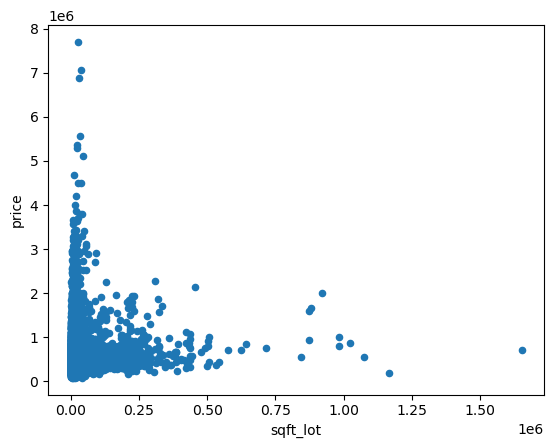

In [12]:
df.plot.scatter(x='bedrooms', y='sqft_living')
df.plot.scatter(x='price', y='sqft_living')
df.plot.scatter(x='price', y='bedrooms')
df.plot.scatter(x='bathrooms', y='bedrooms')
df.plot.scatter(x='sqft_lot', y='price')

### Synthèse des traitements : Doublons, Valeurs manquantes et Aberrantes

**1. Intégrité de la base de données**
* **Valeurs manquantes** : Aucune valeur nulle sur l'ensemble du jeu de données. Aucun traitement d'imputation nécessaire.
* **Doublons stricts** : 0 ligne parfaitement identique.
* **Doublons d'identifiants (`id`)** : 177 biens vendus plusieurs fois. Pour éviter toute fuite de données (*data leakage*) lors de la séparation Train/Test, seule la transaction la plus récente de chaque bien est conservée.

**2. Filtrage des valeurs aberrantes et extrêmes (*Outliers*)**
* **Surfaces habitables (`sqft_living`)** : Suppression des biens dépassant **10 000 sqft**. Cela élimine les points à très fort levier (manoirs exceptionnels) qui fausseraient l'apprentissage des modèles linéaires.
* **Surface du terrain (`sqft_lot`)** : Suppression des terrains dépassant **750 000 sqft** (environ 7 hectares). Cela permet d'exclure la longue traîne des domaines agricoles/forestiers tout en conservant les grandes propriétés résidentielles légitimes.
* **Chambres (`bedrooms`)** : 
  * Suppression de l'erreur matérielle à **33 chambres**.
  * Suppression du bien atypique à **11 chambres** (prix anormalement bas).
  * Biens à **0 chambre** : conservation des surfaces <= 1 500 sqft (assimilables à des studios/lofts) et suppression des surfaces > 1 500 sqft (incohérences).
  * *Note : Les propriétés de 7 à 10 chambres sont conservées car elles reflètent une réalité du marché (colocation, grand locatif).*
* **Salles de bain (`bathrooms`)** : 
  * Suppression des biens déclarant **0 salle de bain** (erreurs de saisie pour des biens résidentiels).
  * *Note : Les biens présentant beaucoup de chambres pour peu de salles de bain sont conservés, car ils reflètent l'architecture de maisons anciennes.*

## Traitement des données
### Traitement pré Power Bi

In [13]:
# 1. Sauvegarde du nombre de lignes initial
nb_lignes_avant = df.shape[0]
print(f"Nombre d'entrées avant nettoyage : {nb_lignes_avant}")

# pipeline de nettoyage
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').drop_duplicates(subset=['id'], keep='last').copy()
df = df[df['bedrooms'] != 33].copy()
df = df[df['bedrooms'] != 11].copy()
df = df[~((df['bedrooms'] == 0) & (df['sqft_living'] > 1500))].copy()
df = df[df['bathrooms'] != 0].copy()
df = df[df['sqft_living'] <= 10000].copy()
df = df[df['sqft_lot'] <= 750000].copy()
# ---------------------------------

# 2. Calcul des lignes restantes et de la différence
nb_lignes_apres = df.shape[0]
lignes_supprimees = nb_lignes_avant - nb_lignes_apres

print(f"Nombre d'entrées après nettoyage : {nb_lignes_apres}")
print(f"Nombre total de lignes supprimées : {lignes_supprimees} (soit environ {lignes_supprimees/nb_lignes_avant*100:.2f}% du dataset)")

Nombre d'entrées avant nettoyage : 21613
Nombre d'entrées après nettoyage : 21408
Nombre total de lignes supprimées : 205 (soit environ 0.95% du dataset)


In [14]:
### Création du dataset pour Power Bi

In [18]:
df.to_csv('../data/king_county_cleaned.csv', index=False)
print("Fichier exporté avec succès dans data/king_county_cleaned.csv")

Fichier exporté avec succès dans data/king_county_cleaned.csv


### Feature engineering

#### Traitement post-EDA sur Power BI

Avant de générer la matrice de corrélation (Pearson), les données doivent être préparées pour garantir des relations pertinentes :

1. **Suppression des identifiants (`id`, `Unnamed: 0`) :** Retrait des variables sans pouvoir prédictif pour éviter le bruit.
2. **Linéarisation de la cible (`price` devient `log_price`) :** L'EDA a montré que la distribution des prix est très asymétrique (une grande majorité de biens « standards » et une longue traîne de villas de luxe à plusieurs millions). Les modèles, particulièrement la régression linéaire, sont très sensibles à ces valeurs extrêmes qui viennent complètement fausser leurs calculs d'erreur. Appliquer un logarithme népérien permet de « tasser » mathématiquement ces très grands nombres pour rapprocher la distribution globale d'une courbe en cloche (loi normale). Cela force l'algorithme à apprendre la logique du marché global plutôt que d'essayer de s'ajuster désespérément à quelques propriétés hors normes.
3. **Feature engineering :**
   - Extraction du mois (`mois_vente`) pour capter la saisonnalité.
   - Remplacement des années brutes (`yr_built`, `yr_renovated`) par des durées explicites (`anciennete`, `age_effectif`, `est_renove`).
4. **Exclusion des variables trompeuses :** Retrait de `zipcode` (variable catégorielle numérique faussant la corrélation) et des variables brutes devenues redondantes.ondantes.

In [15]:
# 1. Histoire du bâti
df['anciennete'] = 2015 - df['yr_built']
df['est_renove'] = (df['yr_renovated'] > 0).astype(int)
df['age_effectif'] = np.where(
    df['yr_renovated'] > 0, 
    2015 - df['yr_renovated'], 
    df['anciennete']
)

# 2. Linéarisation de la cible
df['log_price'] = np.log(df['price'])

# 3. Saisonnalité
df['date'] = pd.to_datetime(df['date'])
df['mois_vente'] = df['date'].dt.month

#### Matrice de Corrélation (Pearson)

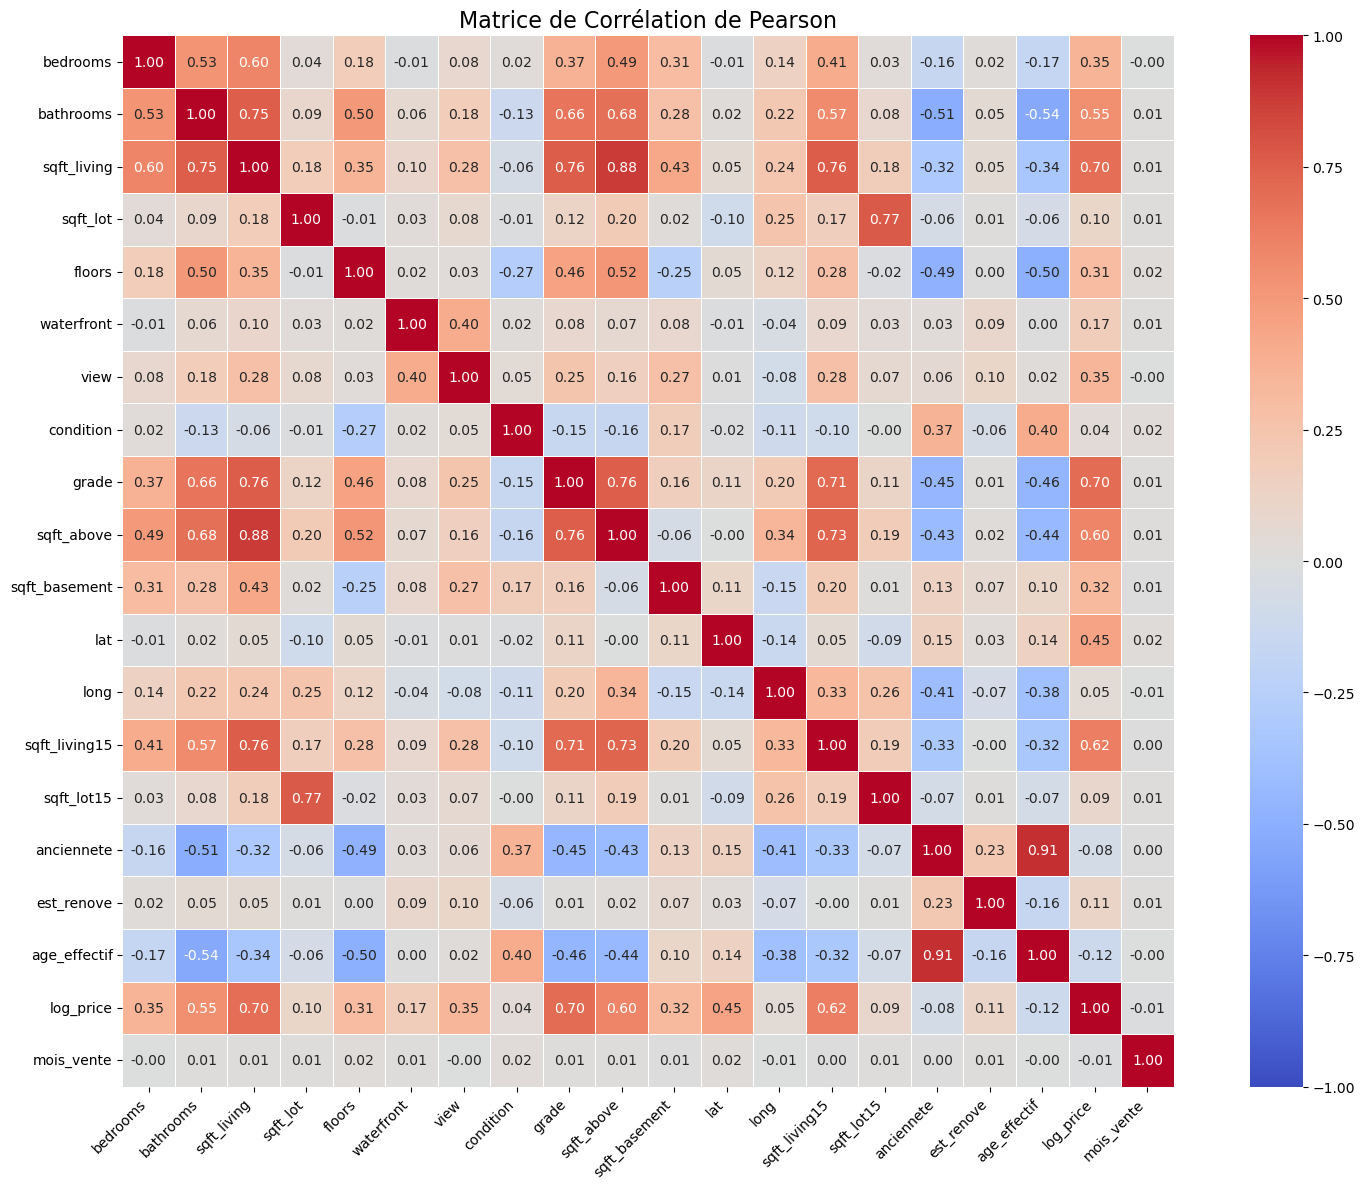

In [16]:
# 1. Exclusion des variables non pertinentes pour Pearson
colonnes_a_exclure = ['Unnamed: 0', 'id', 'price', 'date', 'yr_built', 'yr_renovated', 'zipcode']
df_corr = df.drop(columns=colonnes_a_exclure, errors='ignore')

# 2. Affichage de la matrice
plt.figure(figsize=(16, 12))
sns.heatmap(
    df_corr.corr(method='pearson'), 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, vmax=1, 
    linewidths=0.5, 
    square=True
)
plt.title("Matrice de Corrélation de Pearson", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Analyse de la Matrice de Corrélation

L'analyse de la matrice de corrélation (Pearson) met en évidence les relations linéaires clés et les potentiels problèmes de multicolinéarité avant la modélisation :

**1. Facteurs d'influence principaux sur le prix (`log_price`) :**
- **Qualité et Volume :** `grade` (0.70) et `sqft_living` (0.70) sont les variables les plus corrélées au prix. La qualité de la construction et la surface totale sont les déterminants majeurs.
- **Voisinage et Agencement :** `sqft_living15` (0.62) et `sqft_above` (0.60) confirment l'impact de la surface, tandis que `bathrooms` (0.55) sert d'indicateur du standing.
- **Localisation :** La latitude (`lat`, 0.45) affiche un score très élevé pour une coordonnée spatiale, validant l'impact premium des quartiers nord (ex: Seattle, Bellevue).

**2. Diagnostic de Multicolinéarité (Risques pour la Régression Linéaire) :**
Plusieurs variables présentent de très fortes corrélations entre elles (score > 0.75), ce qui pénalisera les modèles linéaires :
- `sqft_living` vs `sqft_above` (0.88) et vs `sqft_living15` (0.76) : Redondance de l'information de surface.
- `sqft_lot` vs `sqft_lot15` (0.77) : Taille du terrain redondante avec le voisinage.
- `anciennete` vs `age_effectif` (0.91) : Sans surprise, 96% du parc n'étant pas rénové, ces deux variables sont quasi-identiques.

**3. Variables à faible corrélation linéaire :**
- La date (`mois_vente`, -0.01) n'a qu'un impact marginal sous forme de relation linéaire stricte.

**Recommandation de Preprocessing :** Pour la Régression Linéaire (Lasso/Ridge), il faudra supprimer les variables redondantes (`sqft_above`, `sqft_living15`, `sqft_lot15`) pour éviter la multicolinéarité. Les modèles basés sur les arbres (Random Forest, XGBoost) conserveront l'intégralité du dataset.

#### Mise à jour du dataset pour la modélisation

In [ ]:
df.to_csv('../data/king_county_cleaned.csv', index=False)
print("Fichier exporté avec succès dans data/king_county_cleaned.csv")

In [19]:
import os

if os.path.exists('king_county_cleaned.csv'):
    os.remove('king_county_cleaned.csv')
    print("Fichier temporaire supprimé du dossier notebooks/.")

Fichier temporaire supprimé du dossier notebooks/.


In [20]:
def print_tree(startpath, max_depth=2):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        if level > max_depth:
            continue
        indent = ' ' * 4 * (level)
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            # On ignore les fichiers cachés de git ou jupyter
            if not f.startswith('.') and not f.endswith('.pyc'): 
                print(f'{subindent}{f}')

# Affiche l'arborescence du dossier parent
print_tree('..')

../
    README.md
    .git/
        COMMIT_EDITMSG
        config
        description
        FETCH_HEAD
        HEAD
        index
        ORIG_HEAD
        packed-refs
        hooks/
            applypatch-msg.sample
            commit-msg.sample
            fsmonitor-watchman.sample
            post-update.sample
            pre-applypatch.sample
            pre-commit.sample
            pre-merge-commit.sample
            pre-push.sample
            pre-rebase.sample
            pre-receive.sample
            prepare-commit-msg.sample
            push-to-checkout.sample
            sendemail-validate.sample
            update.sample
        info/
            exclude
        logs/
            HEAD
        objects/
        refs/
    data/
        kc_house_data.csv
        king_county_cleaned.csv
    notebooks/
        1_data_exploration_and_cleaning.ipynb
        2_modeling_and_evaluation.ipynb
        .ipynb_checkpoints/
            1_data_exploration_and_cleaning-checkpoint.ipynb
 